# Parallel Hybrid Model — Physics ∥ ML Residuals

## Model definition (updated)

Physics and ML run **in parallel** on the same 4 inputs, then add:

$$
y_{hybrid} = y_{phys} + \hat{y}_{res}
$$

| Branch | Role |
|--------|------|
| **Physics** | Fixed **TEMA Type A** shell & tube (160 tubes, 2-pass, L=6 m, triangular pitch) → `U_phys`, `Taout_phys`, `Twout_phys` via heat-transfer coeffs + E-NTU |
| **Udata (LMTD)** | Ground-truth overall U from dataset temps: `Udata = Qavg / (A · LMTD)` |
| **ML residuals** | Learns corrections: `U_res = Udata − U_phys`, `Taout_res = Taout − Taout_phys`, `Twout_res = Twout − Twout_phys` |
| **Hybrid** | `U_hybrid = U_phys + U_res_pred`, same for outlet temps |

**Inputs:** `m_air`, `m_water`, `T_air_in`, `T_water_in` (from `data.csv`)  
**Outputs:** `U`, `T_air_out`, `T_water_out`  
**U target for training & scoring:** **Udata** (LMTD), not CSV `U_actual`


## 1. Libraries and data


In [15]:
# LIBRARIES AND DATA LOADING
# Parallel hybrid:
#   Physics branch -> U, Taout, Twout (TEMA geometry)
#   Udata from LMTD
#   ML branch -> residual corrections (U vs Udata)
#   Hybrid -> physics + residuals

import math
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")

# Use data.csv from Serial Model folder
DATA_DIR = Path(r"c:\Users\krish\JBS Tech\Heat exchanger Digital Twin\Serial Model")
data_path = DATA_DIR / "data.csv"
if not data_path.exists():
    data_path = Path("data.csv")
if not data_path.exists():
    raise FileNotFoundError("data.csv not found in Serial Model folder")

df_raw = pd.read_csv(data_path, header=1)

if "State" in df_raw.columns:
    df_raw = df_raw[df_raw["State"].astype(str).str.startswith("Case")].copy()

cols = {
    "Hot Air flow in Shell": "m_air_kgh",
    "Cooling water flow in Tubes": "m_water_kgh",
    "1 - Temperature": "T_air_in",
    "3 - Temperature": "T_water_in",
    "2 - Temperature": "T_air_out",
    "4 - Temperature": "T_water_out",
    "E-100 - Overall U": "U_actual",
}

df = df_raw[list(cols.keys())].rename(columns=cols).copy()

for c in df.columns:
    df[c] = pd.to_numeric(df[c], errors="coerce")

df = df.dropna().reset_index(drop=True)

df["m_air"] = df["m_air_kgh"] / 3600.0
df["m_water"] = df["m_water_kgh"] / 3600.0

print("Loaded dataset:", data_path.resolve())
print("Shape:", df.shape)
print(df.head())


Loaded dataset: C:\Users\krish\JBS Tech\Models\Heat exchanger Digital Twin\Serial Model\data.csv
Shape: (7526, 9)
   m_air_kgh  m_water_kgh  T_air_in  T_water_in  T_air_out  T_water_out  \
0    10000.0      10000.0     100.0        25.0      69.25        32.12   
1    10000.0      10000.0     150.0        25.0      98.14        37.10   
2    10000.0      10000.0     200.0        25.0     126.70        42.24   
3    10000.0      10000.0     250.0        25.0     155.00        47.50   
4    10000.0      10000.0     300.0        25.0     183.10        52.89   

   U_actual     m_air   m_water  
0     26.67  2.777778  2.777778  
1     27.33  2.777778  2.777778  
2     27.94  2.777778  2.777778  
3     28.49  2.777778  2.777778  
4     28.98  2.777778  2.777778  


## 2. Physics branch + Udata (LMTD)

**Fixed geometry (TEMA Type A, 2-pass tubes, triangular pitch):**
- `N_TUBES = 160`, `L = 6 m`, `d_o = 0.020 m`, `pitch = 0.050 m`
- Equivalent diameter: `De = 4(0.86 P² − π d_o²/4) / (π d_o)`
- Area: `A = N · π · d_o · L`

**Physics path:** properties → hi/ho → `U_phys` → E-NTU → `Taout_phys`, `Twout_phys`

**Udata (from data, not from physics):**
$$
LMTD = \frac{\Delta T_1 - \Delta T_2}{\ln(\Delta T_1/\Delta T_2)}, \quad
Udata = \frac{Q_{avg}}{A \cdot LMTD}
$$

**Residuals for ML:**
- `U_res = Udata − U_phys`
- `Taout_res = Taout_data − Taout_phys`
- `Twout_res = Twout_data − Twout_phys`


In [16]:
# PHYSICS BRANCH - TEMA Type A shell, 2-pass tubes
# Operating inputs from each dataset row.


# ----- Inlet pressures (absolute, Pa) -----
# data.csv has no pressure columns, so these fixed values are used for every row.
ATM = 101325.0                 # 1 atm in Pa
P_AIR_IN = 1.5 * ATM           # Air inlet pressure (shell side)
P_WATER_IN = 2.0 * ATM         # Water inlet pressure (tube side)


def get_water_saturation_temp(P):
    """Boiling (saturation) temperature of water (C) at pressure P (Pa).
    Antoine equation, two ranges: 1-100 C and 99-374 C."""
    P_mmHg = P / 133.322
    if P_mmHg >= 760.0:
        A, B, C = 8.14019, 1810.94, 244.485
    else:
        A, B, C = 8.07131, 1730.63, 233.426
    return B / (A - math.log10(P_mmHg)) - C


def get_water_properties(T_c, P=P_WATER_IN):
    """Water properties at temperature T_c (C) and pressure P (Pa)."""
    # Liquid range: 1 C up to the boiling point at P
    T = max(1.0, min(T_c, get_water_saturation_temp(P)))
    # Small compression correction (bulk modulus ~2.2 GPa)
    rho = (1000.0 - 0.0178 * abs(T - 4.0) ** 1.7) * (1.0 + (P - ATM) / 2.2e9)
    mu = 0.00179 * math.exp(-0.0247 * T)
    cp = 4182.0 - 0.25 * T
    k = 0.57 + 0.0017 * T
    Pr = (cp * mu) / k
    return rho, mu, cp, k, Pr


def get_air_properties(T_c, P=P_AIR_IN):
    """Air properties at temperature T_c (C) and pressure P (Pa)."""
    T_k = T_c + 273.15
    R_spec = 287.05
    rho = P / (R_spec * T_k)

    mu_ref = 1.716e-5
    T_ref = 273.15
    S = 110.4
    mu = mu_ref * ((T_k / T_ref) ** 1.5) * ((T_ref + S) / (T_k + S))

    cp = 1005.0 + 0.05 * T_c
    k = 0.0241 + 7.5e-5 * T_c
    Pr = (cp * mu) / k
    return rho, mu, cp, k, Pr


# ----- Fixed Geometry (TEMA Type A Shell, 2-Pass Tube) -----
N_TUBES = 160
N_PASSES = 2
L_TUBE = 6.0
D_O = 0.020
WALL_THICKNESS = 0.002
PITCH = 0.050
D_S = 0.387
B_BAFFLE = 0.8
K_WALL = 45.0
R_FI = 0.00015
R_FO = 0.00035

D_I = D_O - 2.0 * WALL_THICKNESS
A_O_TOTAL = N_TUBES * (math.pi * D_O * L_TUBE)
N_TUBES_PER_PASS = N_TUBES / N_PASSES
A_FLOW_TUBE = N_TUBES_PER_PASS * (math.pi * D_I ** 2 / 4)
C_PRIME = PITCH - D_O
A_S = (D_S * C_PRIME * B_BAFFLE) / PITCH
D_E = 4.0 * (0.86 * PITCH ** 2 - (math.pi * D_O ** 2 / 4.0)) / (math.pi * D_O)

A_o_total = A_O_TOTAL
print(f"Fixed geometry A_o = {A_o_total:.4f} m2  (TEMA A, triangular pitch)")


def rate_shell_and_tube_1_2(
    T_air_in,
    m_dot_air,
    T_water_in,
    m_dot_water,
    P_air_in=P_AIR_IN,
    P_water_in=P_WATER_IN,
    tol=1e-5,
    max_iter=100,
    omega=0.5,
):
    """
    Physics rating for one operating point from the dataset.
    Required: T_air_in, m_dot_air, T_water_in, m_dot_water
    Optional: inlet pressures P_air_in, P_water_in (Pa, absolute)
    """
    d_i = D_I
    d_o = D_O
    A_o = A_O_TOTAL
    A_flow_tube = A_FLOW_TUBE
    A_s = A_S
    D_e = D_E

    T_h_out = T_air_in - 30.0
    T_c_out = T_water_in + 10.0

    for iteration in range(1, max_iter + 1):
        T_h_avg = 0.5 * (T_air_in + T_h_out)
        T_c_avg = 0.5 * (T_water_in + T_c_out)

        rho_w, mu_w, cp_w, k_w, Pr_w = get_water_properties(T_c_avg, P_water_in)
        rho_a, mu_a, cp_a, k_a, Pr_a = get_air_properties(T_h_avg, P_air_in)

        u_i = m_dot_water / (rho_w * A_flow_tube)
        Re_i = (rho_w * u_i * d_i) / mu_w
        Nu_i = 0.023 * (Re_i ** 0.8) * (Pr_w ** 0.4)
        h_i = (Nu_i * k_w) / d_i

        G_s = m_dot_air / A_s
        Re_s = (G_s * D_e) / mu_a
        Nu_o = 0.36 * (Re_s ** 0.55) * (Pr_a ** (1.0 / 3.0))
        h_o = (Nu_o * k_a) / D_e

        R_conv_i = (1.0 / h_i) * (d_o / d_i)
        R_foul_i = R_FI * (d_o / d_i)
        R_cond = (d_o * math.log(d_o / d_i)) / (2.0 * K_WALL)
        U_o = 1.0 / (R_conv_i + R_foul_i + R_cond + R_FO + 1.0 / h_o)

        C_h = m_dot_air * cp_a
        C_c = m_dot_water * cp_w
        C_min = min(C_h, C_c)
        C_max = max(C_h, C_c)
        C_r = C_min / C_max

        NTU = (U_o * A_o) / C_min
        E = math.sqrt(1.0 + C_r ** 2)
        exp_term = math.exp(-NTU * E)
        epsilon = 2.0 / (1.0 + C_r + E * ((1.0 + exp_term) / (1.0 - exp_term)))

        Q = epsilon * C_min * (T_air_in - T_water_in)
        T_h_out_new = T_air_in - (Q / C_h)
        T_c_out_new = T_water_in + (Q / C_c)

        diff = max(abs(T_h_out_new - T_h_out), abs(T_c_out_new - T_c_out))
        if diff < tol:
            T_h_out, T_c_out = T_h_out_new, T_c_out_new
            break

        T_h_out = omega * T_h_out_new + (1.0 - omega) * T_h_out
        T_c_out = omega * T_c_out_new + (1.0 - omega) * T_c_out

    return {
        "Iterations_to_Converge": iteration,
        "U_phys": float(U_o),
        "T_air_out_phys": float(T_h_out),
        "T_water_out_phys": float(T_c_out),
        "P_air_in_kPa": float(P_air_in / 1000.0),
        "P_water_in_kPa": float(P_water_in / 1000.0),
        "Q_kW": float(Q / 1000.0),
        "NTU": float(NTU),
        "epsilon": float(epsilon),
        "A_o_total": float(A_o),
    }


_row0 = df.iloc[0]
demo = rate_shell_and_tube_1_2(
    T_air_in=float(_row0["T_air_in"]),
    m_dot_air=float(_row0["m_air"]),
    T_water_in=float(_row0["T_water_in"]),
    m_dot_water=float(_row0["m_water"]),
)
print("Demo using dataset row 0:")
for k, v in demo.items():
    print(f"  {k}: {v}")


Fixed geometry A_o = 60.3186 m2  (TEMA A, triangular pitch)
Demo using dataset row 0:
  Iterations_to_Converge: 21
  U_phys: 39.228343360852435
  T_air_out_phys: 60.083113964461724
  T_water_out_phys: 34.64805282282843
  P_air_in_kPa: 151.9875
  P_water_in_kPa: 202.65
  Q_kW: 111.87839155123004
  NTU: 0.8442314162900545
  epsilon: 0.5322251471405103
  A_o_total: 60.318578948924035


In [17]:
# 1) CALCULATE Udata FROM DATASET USING LMTD
# 2) RUN PHYSICS BRANCH ON EVERY ROW
# 3) Residuals:
#      U_res     = Udata - U_phys
#      Taout_res = Taout_actual - Taout_phys
#      Twout_res = Twout_actual - Twout_phys


def lmtd_counterflow(T_air_in, T_water_in, T_air_out, T_water_out, eps=1e-8):
    """LMTD = (dT1 - dT2) / ln(dT1/dT2)."""
    dT1 = T_air_in - T_water_out
    dT2 = T_air_out - T_water_in
    if dT1 <= eps or dT2 <= eps:
        return float("nan")
    if abs(dT1 - dT2) < eps:
        return 0.5 * (dT1 + dT2)
    return (dT1 - dT2) / math.log(dT1 / dT2)


def udata_from_lmtd(m_air, m_water, T_air_in, T_water_in, T_air_out, T_water_out, A=None):
    """Overall U from dataset temperatures via LMTD."""
    if A is None:
        A = A_o_total

    LMTD = lmtd_counterflow(T_air_in, T_water_in, T_air_out, T_water_out)
    if not math.isfinite(LMTD) or LMTD <= 0.0 or A <= 0.0:
        return float("nan")

    Thavg = 0.5 * (T_air_out + T_air_in)
    Tcavg = 0.5 * (T_water_in + T_water_out)

    _, _, Cp_h, _, _ = get_air_properties(Thavg)
    _, _, Cp_c, _, _ = get_water_properties(Tcavg)

    Qh = m_air * Cp_h * (T_air_in - T_air_out)
    Qc = m_water * Cp_c * (T_water_out - T_water_in)
    Qavg = 0.5 * (Qh + Qc)

    return Qavg / (A * LMTD)


Udata_list = []
for _, row in df.iterrows():
    Udata_list.append(
        udata_from_lmtd(
            m_air=float(row["m_air"]),
            m_water=float(row["m_water"]),
            T_air_in=float(row["T_air_in"]),
            T_water_in=float(row["T_water_in"]),
            T_air_out=float(row["T_air_out"]),
            T_water_out=float(row["T_water_out"]),
            A=A_o_total,
        )
    )
df["Udata"] = Udata_list

print("Udata calculated for", len(df), "rows | A =", round(A_o_total, 4), "m2")
print(df[["T_air_in", "T_air_out", "T_water_in", "T_water_out", "U_actual", "Udata"]].head(8).to_string(index=False))
print("\nUdata stats:")
print(df["Udata"].describe().round(3))

# --- Physics on every row ---
U_phys_list, Ta_phys_list, Tw_phys_list, it_list = [], [], [], []

for i, row in df.iterrows():
    res = rate_shell_and_tube_1_2(
        T_air_in=float(row["T_air_in"]),
        m_dot_air=float(row["m_air"]),
        T_water_in=float(row["T_water_in"]),
        m_dot_water=float(row["m_water"]),
    )
    U_phys_list.append(res["U_phys"])
    Ta_phys_list.append(res["T_air_out_phys"])
    Tw_phys_list.append(res["T_water_out_phys"])
    it_list.append(res["Iterations_to_Converge"])

    if (i + 1) % 1000 == 0:
        print(f"Physics processed {i + 1}/{len(df)} rows...")

df["U_phys"] = U_phys_list
df["T_air_out_phys"] = Ta_phys_list
df["T_water_out_phys"] = Tw_phys_list
df["iterations"] = it_list

# Residuals for ML (U vs Udata)
df["U_res"] = df["Udata"] - df["U_phys"]
df["T_air_out_res"] = df["T_air_out"] - df["T_air_out_phys"]
df["T_water_out_res"] = df["T_water_out"] - df["T_water_out_phys"]

df = df.dropna(subset=["Udata", "U_res"]).reset_index(drop=True)

print("Done. Mean iterations:", round(df["iterations"].mean(), 2))
print("\nResidual stats (Udata/actual - physics):")
print(df[["U_res", "T_air_out_res", "T_water_out_res"]].describe().round(3))


Udata calculated for 7526 rows | A = 60.3186 m2
 T_air_in  T_air_out  T_water_in  T_water_out  U_actual     Udata
    100.0      69.25        25.0        32.12     26.67 25.333225
    150.0      98.14        25.0        37.10     27.33 25.882739
    200.0     126.70        25.0        42.24     27.94 26.367904
    250.0     155.00        25.0        47.50     28.49 26.790825
    300.0     183.10        25.0        52.89     28.98 27.180132
    350.0     211.20        25.0        58.37     29.43 27.500098
    400.0     239.20        25.0        63.92     29.83 27.784916
    450.0     267.10        25.0        69.55     30.19 28.050635

Udata stats:
count    7526.000
mean       99.926
std        39.863
min        16.081
25%        67.937
50%       102.302
75%       132.587
max       194.354
Name: Udata, dtype: float64
Physics processed 1000/7526 rows...
Physics processed 2000/7526 rows...
Physics processed 3000/7526 rows...
Physics processed 4000/7526 rows...
Physics processed 5000/7526 

## 3. ML branch — residual models

ML does **not** predict U or temps directly. It predicts the gap between physics and data:

| Residual | Formula |
|----------|---------|
| `U_res` | `Udata − U_phys` |
| `Taout_res` | `Taout_data − Taout_phys` |
| `Twout_res` | `Twout_data − Twout_phys` |

Features: `(m_air, m_water, T_air_in, T_water_in)`. Best model by mean test R² is selected.

Compare **Linear Regression** vs **Random Forest** (multi-output), pick the better test R2.


In [18]:
# ML BRANCH - learn residuals of U (vs Udata), Taout, Twout

feature_cols = ["m_air", "m_water", "T_air_in", "T_water_in"]
residual_cols = ["U_res", "T_air_out_res", "T_water_out_res"]

X = df[feature_cols].values
y_res = df[residual_cols].values

X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
    X, y_res, df.index.values, test_size=0.2, random_state=42
)


def eval_residual_model(name, model, X_tr, y_tr, X_te, y_te):
    """Train multi-output residual model; report per-target and mean test R²."""
    model.fit(X_tr, y_tr)
    pred_tr = model.predict(X_tr)
    pred_te = model.predict(X_te)

    labels = ["U_res", "Taout_res", "Twout_res"]
    train_r2s, test_r2s, test_maes, test_rmses = [], [], [], []

    print(f"\n{name}")
    for j, lab in enumerate(labels):
        tr = r2_score(y_tr[:, j], pred_tr[:, j])
        te = r2_score(y_te[:, j], pred_te[:, j])
        mae = mean_absolute_error(y_te[:, j], pred_te[:, j])
        rmse = float(np.sqrt(mean_squared_error(y_te[:, j], pred_te[:, j])))
        train_r2s.append(tr)
        test_r2s.append(te)
        test_maes.append(mae)
        test_rmses.append(rmse)
        print(f"  {lab:10s}  Train R²={tr:.4f}  Test R²={te:.4f}  MAE={mae:.3f}  RMSE={rmse:.3f}")

    mean_test_r2 = float(np.mean(test_r2s))
    mean_test_rmse = float(np.mean(test_rmses))
    print(f"  Mean test R² = {mean_test_r2:.4f}")

    return {
        "name": name,
        "model": model,
        "train_r2": train_r2s,
        "test_r2": test_r2s,
        "test_mae": test_maes,
        "test_rmse": test_rmses,
        "mean_test_r2": mean_test_r2,
        "mean_test_rmse": mean_test_rmse,
        "pred_test": pred_te,
    }


print("=" * 55)
print("RESIDUAL MODEL COMPARISON")
print("=" * 55)

lin_res = MultiOutputRegressor(LinearRegression())
lin_metrics = eval_residual_model(
    "1) Linear Regression (multi-output)", lin_res, X_train, y_train, X_test, y_test
)

rf_res = MultiOutputRegressor(
    RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=1,
    )
)
rf_metrics = eval_residual_model(
    "2) Random Forest (multi-output)", rf_res, X_train, y_train, X_test, y_test
)

candidates = [lin_metrics, rf_metrics]
best = max(candidates, key=lambda m: (m["mean_test_r2"], -m["mean_test_rmse"]))
ml_residual = best["model"]

print("\n" + "-" * 55)
print(f"SELECTED RESIDUAL MODEL: {best['name']}")
print(f"  Reason: highest mean test R² = {best['mean_test_r2']:.4f}")
print("-" * 55)

compare_df = pd.DataFrame(
    [
        {
            "Model": m["name"],
            "Mean Test R²": round(m["mean_test_r2"], 4),
            "U_res Test R²": round(m["test_r2"][0], 4),
            "Taout_res Test R²": round(m["test_r2"][1], 4),
            "Twout_res Test R²": round(m["test_r2"][2], 4),
            "Selected": "YES" if m is best else "",
        }
        for m in candidates
    ]
)
print("\nComparison table:")
print(compare_df.to_string(index=False))


RESIDUAL MODEL COMPARISON

1) Linear Regression (multi-output)
  U_res       Train R²=0.7265  Test R²=0.7280  MAE=5.378  RMSE=7.641
  Taout_res   Train R²=0.6881  Test R²=0.7057  MAE=9.351  RMSE=13.016
  Twout_res   Train R²=0.3765  Test R²=0.3601  MAE=12.088  RMSE=19.074
  Mean test R² = 0.5979

2) Random Forest (multi-output)
  U_res       Train R²=0.9991  Test R²=0.9981  MAE=0.313  RMSE=0.645
  Taout_res   Train R²=0.9996  Test R²=0.9992  MAE=0.329  RMSE=0.693
  Twout_res   Train R²=0.9988  Test R²=0.9970  MAE=0.469  RMSE=1.299
  Mean test R² = 0.9981

-------------------------------------------------------
SELECTED RESIDUAL MODEL: 2) Random Forest (multi-output)
  Reason: highest mean test R² = 0.9981
-------------------------------------------------------

Comparison table:
                              Model  Mean Test R²  U_res Test R²  Taout_res Test R²  Twout_res Test R² Selected
1) Linear Regression (multi-output)        0.5979         0.7280             0.7057             0.

## 4. Parallel hybrid assembly

Both branches use the **same 4 inputs** at inference:

```
inputs ──┬──► Physics (TEMA) ──► U_phys, Taout_phys, Twout_phys
         │
         └──► ML (residuals) ──► U_res_pred, Taout_res_pred, Twout_res_pred
                    │
                    ▼
         y_hybrid = y_phys + y_res_pred
```

- `U_hybrid` is pulled toward **Udata** (LMTD ground truth)
- Outlet hybrids are pulled toward dataset outlet temperatures


In [19]:
# PARALLEL HYBRID
# Physics branch  -> U_phys, Ta_phys, Tw_phys
# ML branch        -> dU, dTa, dTw  (predicted residuals)
# Hybrid outputs   -> physics + residual


def physics_branch(m_air, m_water, T_air_in, T_water_in,
                   P_air_in=P_AIR_IN, P_water_in=P_WATER_IN):
    """TEMA Type A physics. Mass flows in kg/s, pressures in Pa."""
    return rate_shell_and_tube_1_2(
        T_air_in=float(T_air_in),
        m_dot_air=float(m_air),
        T_water_in=float(T_water_in),
        m_dot_water=float(m_water),
        P_air_in=P_air_in,
        P_water_in=P_water_in,
    )


def ml_residual_branch(m_air, m_water, T_air_in, T_water_in):
    """Predict residuals [dU, dTa, dTw] from the 4 inputs."""
    pred = ml_residual.predict([[m_air, m_water, T_air_in, T_water_in]])[0]
    return {
        "U_res_pred": float(pred[0]),
        "T_air_out_res_pred": float(pred[1]),
        "T_water_out_res_pred": float(pred[2]),
    }


def parallel_hybrid_predict(m_air, m_water, T_air_in, T_water_in, phys=None,
                            P_air_in=P_AIR_IN, P_water_in=P_WATER_IN):
    """
    Parallel hybrid prediction.
    If phys is provided (dict from physics_branch), reuse it to avoid recompute.
    """
    if phys is None:
        phys = physics_branch(m_air, m_water, T_air_in, T_water_in, P_air_in, P_water_in)
    res = ml_residual_branch(m_air, m_water, T_air_in, T_water_in)

    return {
        "U_phys": phys["U_phys"],
        "T_air_out_phys": phys["T_air_out_phys"],
        "T_water_out_phys": phys["T_water_out_phys"],
        "U_res_pred": res["U_res_pred"],
        "T_air_out_res_pred": res["T_air_out_res_pred"],
        "T_water_out_res_pred": res["T_water_out_res_pred"],
        "U_hybrid": phys["U_phys"] + res["U_res_pred"],
        "T_air_out_hybrid": phys["T_air_out_phys"] + res["T_air_out_res_pred"],
        "T_water_out_hybrid": phys["T_water_out_phys"] + res["T_water_out_res_pred"],
        "Q_kW": phys["Q_kW"],
        "NTU": phys["NTU"],
        "epsilon": phys["epsilon"],
    }


# Evaluate on TEST rows (reuse precomputed physics columns)
test_df = df.loc[idx_test].copy().reset_index(drop=True)

U_hyb, Ta_hyb, Tw_hyb = [], [], []
U_res_p, Ta_res_p, Tw_res_p = [], [], []

for i, row in test_df.iterrows():
    phys = {
        "U_phys": float(row["U_phys"]),
        "T_air_out_phys": float(row["T_air_out_phys"]),
        "T_water_out_phys": float(row["T_water_out_phys"]),
        "Q_kW": np.nan,
        "NTU": np.nan,
        "epsilon": np.nan,
    }
    out = parallel_hybrid_predict(
        row["m_air"], row["m_water"], row["T_air_in"], row["T_water_in"], phys=phys
    )
    U_hyb.append(out["U_hybrid"])
    Ta_hyb.append(out["T_air_out_hybrid"])
    Tw_hyb.append(out["T_water_out_hybrid"])
    U_res_p.append(out["U_res_pred"])
    Ta_res_p.append(out["T_air_out_res_pred"])
    Tw_res_p.append(out["T_water_out_res_pred"])

test_df["U_hybrid"] = U_hyb
test_df["T_air_out_hybrid"] = Ta_hyb
test_df["T_water_out_hybrid"] = Tw_hyb
test_df["U_res_pred"] = U_res_p
test_df["T_air_out_res_pred"] = Ta_res_p
test_df["T_water_out_res_pred"] = Tw_res_p

print(f"Parallel hybrid predictions complete: {len(test_df)} test rows")
print(f"Residual model used: {best['name']}")


Parallel hybrid predictions complete: 1506 test rows
Residual model used: 2) Random Forest (multi-output)


## 5. Parallel model prediction vs data (before clipping)

Parallel hybrid outputs on the test set: `U` vs Udata, hot fluid outlet, cold fluid outlet.
This runs **before** the clip cell, so the cold fluid outlet shows the raw values.

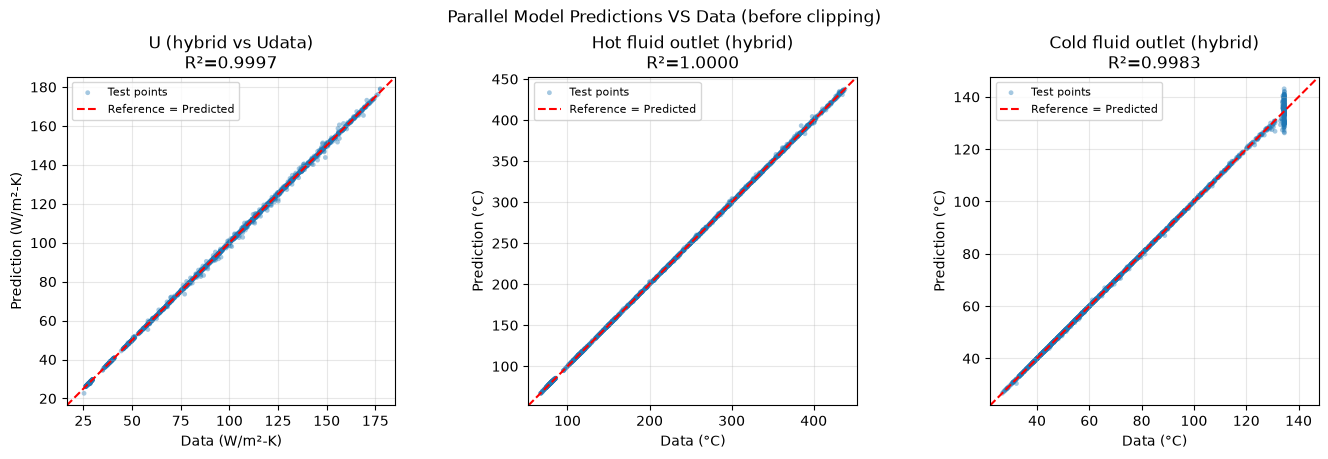

In [20]:
# PARALLEL MODEL PREDICTION vs DATA (test set) — BEFORE clipping
# Points on the red dashed line (y = x) are perfect predictions.


def plot_parallel_vs_data(stage):
    """1x3 parity plots of the parallel hybrid: U vs Udata, hot and cold fluid outlets."""
    pairs = [
        ("Udata", "U_hybrid", "U (hybrid vs Udata)", "W/m²-K"),
        ("T_air_out", "T_air_out_hybrid", "Hot fluid outlet (hybrid)", "°C"),
        ("T_water_out", "T_water_out_hybrid", "Cold fluid outlet (hybrid)", "°C"),
    ]

    fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
    for ax, (actual_col, pred_col, name, unit) in zip(axes, pairs):
        y_true = test_df[actual_col].to_numpy(dtype=float)
        y_pred = test_df[pred_col].to_numpy(dtype=float)
        r2 = r2_score(y_true, y_pred)

        ax.scatter(y_true, y_pred, s=12, alpha=0.4, edgecolors="none", label="Test points")
        lo = min(y_true.min(), y_pred.min())
        hi = max(y_true.max(), y_pred.max())
        pad = 0.04 * (hi - lo if hi > lo else 1.0)
        ax.plot(
            [lo - pad, hi + pad],
            [lo - pad, hi + pad],
            "r--",
            lw=1.5,
            label="Reference = Predicted",
        )
        ax.set_xlim(lo - pad, hi + pad)
        ax.set_ylim(lo - pad, hi + pad)
        ax.set_xlabel(f"Data ({unit})")
        ax.set_ylabel(f"Prediction ({unit})")
        ax.set_title(f"{name}\nR²={r2:.4f}")
        ax.grid(True, alpha=0.3)
        ax.legend(loc="upper left", fontsize=8)
        ax.set_aspect("equal", adjustable="box")

    plt.suptitle(f"Parallel Model Predictions VS Data ({stage})")
    plt.tight_layout()
    plt.show()


plot_parallel_vs_data("before clipping")


In [21]:
# =====================================================================
# CLIP WATER OUTLET AT SATURATION TEMPERATURE  (separate post-processing)
# =====================================================================
# In data.csv the water outlet never goes above ~134.6 °C: at the water-side
# pressure (~3 bar) the water starts boiling, and extra heat goes into
# evaporation instead of raising the temperature.
# Physics (and physics + residual) treats water as liquid only, so it can
# predict values above this. Here we simply cap the test-set predictions
# at T_SAT_WATER. Training residuals and the models are NOT changed —
# delete/skip this cell to undo.

T_SAT_WATER = 134.6   # °C, max water outlet seen in data.csv

for col in ["T_water_out_phys", "T_water_out_hybrid"]:
    # Keep the original (unclipped) prediction for reference
    test_df[col + "_raw"] = test_df[col]

    # Cap the prediction at the saturation temperature
    test_df[col] = test_df[col + "_raw"].clip(upper=T_SAT_WATER)

    n_clipped = int((test_df[col + "_raw"] > T_SAT_WATER).sum())
    print(f"{col}: clipped {n_clipped} of {len(test_df)} test rows at T_sat = {T_SAT_WATER} °C")
# ====================== END OF CLIP SECTION ==========================


T_water_out_phys: clipped 208 of 1506 test rows at T_sat = 134.6 °C
T_water_out_hybrid: clipped 91 of 1506 test rows at T_sat = 134.6 °C


## 6. Parallel model prediction vs data (after clipping)

Same plot as section 5, after the clip cell (cold fluid outlet capped at `T_SAT_WATER`).

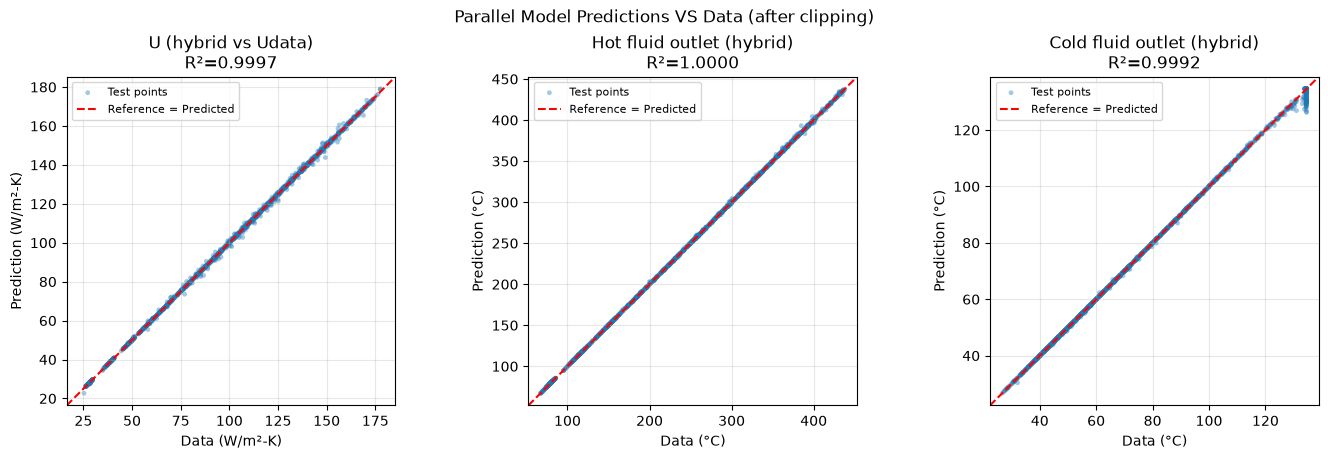

In [22]:
# PARALLEL MODEL PREDICTION vs DATA (test set) — AFTER clipping
# Uses plot_parallel_vs_data from section 5.

plot_parallel_vs_data("after clipping")


## 7. Evaluate

Compare **physics-only** vs **parallel hybrid** on the held-out test set:

- **U** scored against **Udata** (LMTD)
- **Taout / Twout** scored against dataset outlet temperatures


In [23]:
# EVALUATE: physics-only vs parallel hybrid on the test set
# U scored against Udata (LMTD). Outlets scored against dataset temps.


def report(name, y_true, y_pred, unit=""):
    r2 = r2_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    print(f"{name:28s}  R²={r2:.4f}  MAE={mae:.3f}{unit}  RMSE={rmse:.3f}{unit}")
    return r2, mae, rmse


print("PHYSICS-ONLY vs PARALLEL HYBRID (test set)")
print("-" * 72)
print("\nPhysics-only:")
report("U (physics vs Udata)", test_df["Udata"], test_df["U_phys"], " W/m²-K")
report("Taout (physics)", test_df["T_air_out"], test_df["T_air_out_phys"], " °C")
report("Twout (physics)", test_df["T_water_out"], test_df["T_water_out_phys"], " °C")

print("\nParallel hybrid (physics + residual):")
report("U (hybrid vs Udata)", test_df["Udata"], test_df["U_hybrid"], " W/m²-K")
report("Taout (hybrid)", test_df["T_air_out"], test_df["T_air_out_hybrid"], " °C")
report("Twout (hybrid)", test_df["T_water_out"], test_df["T_water_out_hybrid"], " °C")

print("\nSample comparisons:")
print(
    test_df[
        [
            "m_air_kgh",
            "m_water_kgh",
            "T_air_in",
            "T_water_in",
            "Udata",
            "U_phys",
            "U_hybrid",
            "T_air_out",
            "T_air_out_phys",
            "T_air_out_hybrid",
            "T_water_out",
            "T_water_out_phys",
            "T_water_out_hybrid",
        ]
    ]
    .head(8)
    .to_string(index=False)
)


def metric_row(name, unit, y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    return {
        "Output": name,
        "Unit": unit,
        "R2": r2_score(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
    }


eval_matrix = pd.DataFrame(
    [
        metric_row("U (physics vs Udata)", "W/m²-K", test_df["Udata"], test_df["U_phys"]),
        metric_row("U (hybrid vs Udata)", "W/m²-K", test_df["Udata"], test_df["U_hybrid"]),
        metric_row("Taout (physics)", "°C", test_df["T_air_out"], test_df["T_air_out_phys"]),
        metric_row("Taout (hybrid)", "°C", test_df["T_air_out"], test_df["T_air_out_hybrid"]),
        metric_row("Twout (physics)", "°C", test_df["T_water_out"], test_df["T_water_out_phys"]),
        metric_row("Twout (hybrid)", "°C", test_df["T_water_out"], test_df["T_water_out_hybrid"]),
    ]
)

print("\nEvaluation matrix (test set)")
print(eval_matrix.to_string(index=False, float_format=lambda v: f"{v:.4f}"))


PHYSICS-ONLY vs PARALLEL HYBRID (test set)
------------------------------------------------------------------------

Physics-only:
U (physics vs Udata)          R²=0.7550  MAE=16.271 W/m²-K  RMSE=19.733 W/m²-K
Taout (physics)               R²=0.9312  MAE=17.098 °C  RMSE=27.838 °C
Twout (physics)               R²=0.9681  MAE=3.748 °C  RMSE=5.679 °C

Parallel hybrid (physics + residual):
U (hybrid vs Udata)           R²=0.9997  MAE=0.313 W/m²-K  RMSE=0.645 W/m²-K
Taout (hybrid)                R²=1.0000  MAE=0.329 °C  RMSE=0.693 °C
Twout (hybrid)                R²=0.9992  MAE=0.285 °C  RMSE=0.899 °C

Sample comparisons:
 m_air_kgh  m_water_kgh  T_air_in  T_water_in      Udata     U_phys   U_hybrid  T_air_out  T_air_out_phys  T_air_out_hybrid  T_water_out  T_water_out_phys  T_water_out_hybrid
   80000.0      45000.0     100.0        35.0 133.413285 119.528393 133.466770      81.13       83.154123         81.159489        42.77         42.246549           42.785023
   25000.0      35000.0  

## 8. Feature importance (ML residual model)


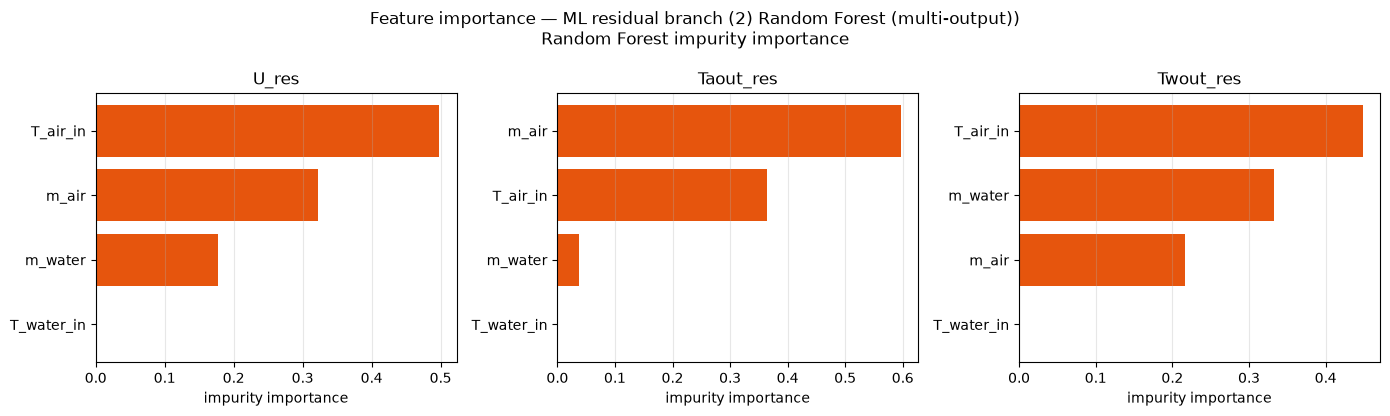

In [24]:
# FEATURE IMPORTANCE of the selected residual ML model
# Random Forest -> impurity importance per residual output
# Linear / other -> permutation importance (ΔR²) per residual output

feature_labels = np.array(["m_air", "m_water", "T_air_in", "T_water_in"])
residual_names = ["U_res", "Taout_res", "Twout_res"]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
estimators = getattr(ml_residual, "estimators_", None)
use_impurity = (
    estimators is not None
    and all(hasattr(est, "feature_importances_") for est in estimators)
)

if use_impurity:
    kind = "Random Forest impurity importance"
    for ax, est, name in zip(axes, estimators, residual_names):
        imp = np.asarray(est.feature_importances_, dtype=float)
        order = np.argsort(imp)
        ax.barh(feature_labels[order], imp[order], color="#e6550d")
        ax.set_xlabel("impurity importance")
        ax.set_title(name)
        ax.grid(True, axis="x", alpha=0.3)
else:
    kind = "permutation importance (ΔR²)"
    rng = np.random.RandomState(42)
    for ax, j, name in zip(axes, range(3), residual_names):
        base_pred = ml_residual.predict(X_test)[:, j]
        base_r2 = r2_score(y_test[:, j], base_pred)
        imp = np.zeros(X_test.shape[1])
        err = np.zeros(X_test.shape[1])
        for f in range(X_test.shape[1]):
            drops = []
            for _ in range(20):
                X_perm = X_test.copy()
                X_perm[:, f] = rng.permutation(X_perm[:, f])
                pred = ml_residual.predict(X_perm)[:, j]
                drops.append(base_r2 - r2_score(y_test[:, j], pred))
            imp[f] = np.mean(drops)
            err[f] = np.std(drops)
        order = np.argsort(imp)
        ax.barh(
            feature_labels[order],
            imp[order],
            xerr=err[order],
            color="#2c7fb8",
            ecolor="#08306b",
            capsize=3,
        )
        ax.set_xlabel("permutation importance (ΔR²)")
        ax.set_title(name)
        ax.grid(True, axis="x", alpha=0.3)

plt.suptitle(f"Feature importance — ML residual branch ({best['name']})\n{kind}")
plt.tight_layout()
plt.show()


## 9. Dataset vs predicted (hybrid, after clipping)

Parallel hybrid only: `U` vs Udata, hot fluid outlet, cold fluid outlet.


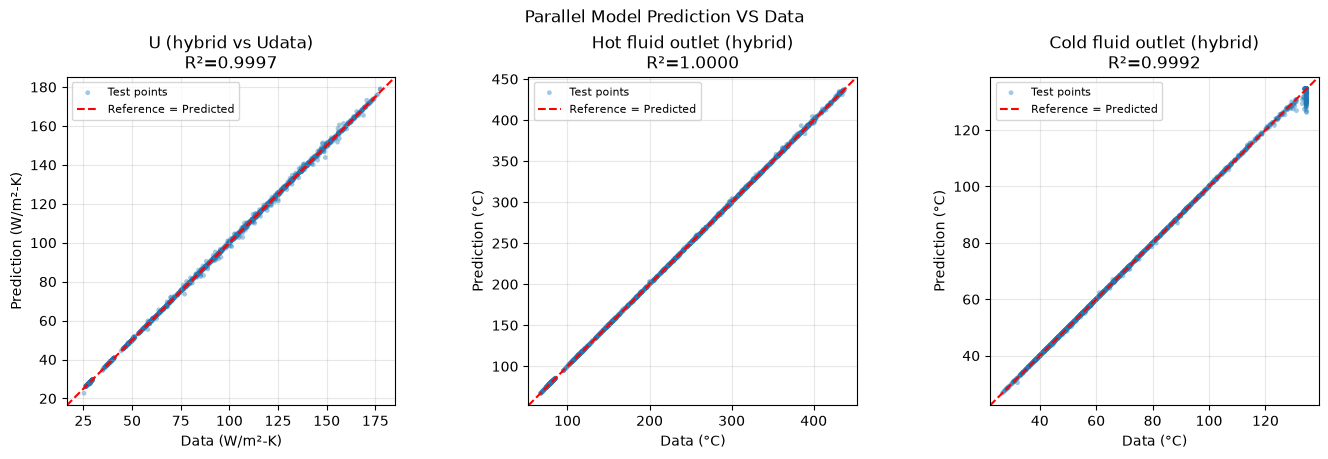

In [25]:
# ACTUAL vs PREDICTED (test set) - parallel hybrid only
# U vs Udata, hot fluid outlet, cold fluid outlet

pairs = [
    ("Udata", "U_hybrid", "U (hybrid vs Udata)", "W/m²-K"),
    ("T_air_out", "T_air_out_hybrid", "Hot fluid outlet (hybrid)", "°C"),
    ("T_water_out", "T_water_out_hybrid", "Cold fluid outlet (hybrid)", "°C"),
]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, (actual_col, pred_col, name, unit) in zip(axes, pairs):
    y_true = test_df[actual_col].to_numpy(dtype=float)
    y_pred = test_df[pred_col].to_numpy(dtype=float)
    r2 = r2_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))

    ax.scatter(y_true, y_pred, s=12, alpha=0.4, edgecolors="none", label="Test points")
    lo = min(y_true.min(), y_pred.min())
    hi = max(y_true.max(), y_pred.max())
    pad = 0.04 * (hi - lo if hi > lo else 1.0)
    ax.plot(
        [lo - pad, hi + pad],
        [lo - pad, hi + pad],
        "r--",
        lw=1.5,
        label="Reference = Predicted",
    )
    ax.set_xlim(lo - pad, hi + pad)
    ax.set_ylim(lo - pad, hi + pad)
    ax.set_xlabel(f"Data ({unit})")
    ax.set_ylabel(f"Prediction ({unit})")
    ax.set_title(f"{name}\nR²={r2:.4f}")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper left", fontsize=8)
    ax.set_aspect("equal", adjustable="box")

plt.suptitle("Parallel Model Prediction VS Data")
plt.tight_layout()
plt.show()


## 10. Digital Twin

Enter `m_air`, `m_water`, `T_air_in`, `T_water_in` → parallel hybrid returns:
- `U_hybrid = U_phys + U_res_pred` (toward Udata)
- `Taout_hybrid`, `Twout_hybrid` (toward dataset outlets)


In [26]:
# DIGITAL TWIN - parallel hybrid
# User gives mass flows (kg/h) and inlet temperatures (C).
# Returns U, Taout, Twout = TEMA physics + residual (U toward Udata).


def digital_twin(m_air_kgh, m_water_kgh, T_air_in, T_water_in,
                 P_air_in_atm=P_AIR_IN / ATM, P_water_in_atm=P_WATER_IN / ATM, verbose=True):
    """
    Parallel hybrid digital twin for the shell-and-tube heat exchanger.

    Inputs (same units as data.csv):
      - m_air_kgh, m_water_kgh       : mass flows in kg/h
      - T_air_in, T_water_in         : inlet temperatures in °C
      - P_air_in_atm, P_water_in_atm : inlet pressures in atm (absolute)
    """
    m_air = m_air_kgh / 3600.0
    m_water = m_water_kgh / 3600.0

    out = parallel_hybrid_predict(
        m_air, m_water, T_air_in, T_water_in,
        P_air_in=P_air_in_atm * ATM, P_water_in=P_water_in_atm * ATM,
    )

    if verbose:
        print("==========================================")
        print("  DIGITAL TWIN — PARALLEL HYBRID")
        print(f"  Residual model: {best['name']}")
        print("  TEMA Physics || ML(residuals vs Udata) -> hybrid")
        print("==========================================")
        print("\nINPUTS")
        print(f"  Air mass flow      : {m_air_kgh:.2f} kg/h  ({m_air:.4f} kg/s)")
        print(f"  Water mass flow    : {m_water_kgh:.2f} kg/h  ({m_water:.4f} kg/s)")
        print(f"  Air inlet temp     : {T_air_in:.2f} °C")
        print(f"  Water inlet temp   : {T_water_in:.2f} °C")
        print(f"  Air inlet press.   : {P_air_in_atm:.2f} atm  ({P_air_in_atm * ATM / 1000.0:.2f} kPa)")
        print(f"  Water inlet press. : {P_water_in_atm:.2f} atm  ({P_water_in_atm * ATM / 1000.0:.2f} kPa)")
        print("\nPHYSICS BRANCH")
        print(f"  U_phys             : {out['U_phys']:.2f} W/m²-K")
        print(f"  Taout_phys         : {out['T_air_out_phys']:.2f} °C")
        print(f"  Twout_phys         : {out['T_water_out_phys']:.2f} °C")
        print("\nML RESIDUAL BRANCH")
        print(f"  dU                 : {out['U_res_pred']:+.3f} W/m²-K")
        print(f"  dTaout             : {out['T_air_out_res_pred']:+.3f} °C")
        print(f"  dTwout             : {out['T_water_out_res_pred']:+.3f} °C")
        print("\nHYBRID OUTPUTS")
        print(f"  Overall U          : {out['U_hybrid']:.2f} W/m²-K")
        print(f"  Air outlet temp    : {out['T_air_out_hybrid']:.2f} °C")
        print(f"  Water outlet temp  : {out['T_water_out_hybrid']:.2f} °C")
        print(f"  Duty (physics)     : {out['Q_kW']:.2f} kW")

    return out


# Example (Case 1 style)
_ = digital_twin(10000, 10000, 100, 25)


  DIGITAL TWIN — PARALLEL HYBRID
  Residual model: 2) Random Forest (multi-output)
  TEMA Physics || ML(residuals vs Udata) -> hybrid

INPUTS
  Air mass flow      : 10000.00 kg/h  (2.7778 kg/s)
  Water mass flow    : 10000.00 kg/h  (2.7778 kg/s)
  Air inlet temp     : 100.00 °C
  Water inlet temp   : 25.00 °C
  Air inlet press.   : 1.50 atm  (151.99 kPa)
  Water inlet press. : 2.00 atm  (202.65 kPa)

PHYSICS BRANCH
  U_phys             : 39.23 W/m²-K
  Taout_phys         : 60.08 °C
  Twout_phys         : 34.65 °C

ML RESIDUAL BRANCH
  dU                 : -16.592 W/m²-K
  dTaout             : +8.452 °C
  dTwout             : -4.234 °C

HYBRID OUTPUTS
  Overall U          : 22.64 W/m²-K
  Air outlet temp    : 68.54 °C
  Water outlet temp  : 30.41 °C
  Duty (physics)     : 111.88 kW


In [27]:
# --- USER INPUT: change values and re-run ---
user_m_air_kgh = 23901     # kg/h
user_m_water_kgh = 21701    # kg/h
user_T_air_in = 330         # °C
user_T_water_in = 35        # °C

twin = digital_twin(
    user_m_air_kgh,
    user_m_water_kgh,
    user_T_air_in,
    user_T_water_in,
)


  DIGITAL TWIN — PARALLEL HYBRID
  Residual model: 2) Random Forest (multi-output)
  TEMA Physics || ML(residuals vs Udata) -> hybrid

INPUTS
  Air mass flow      : 23901.00 kg/h  (6.6392 kg/s)
  Water mass flow    : 21701.00 kg/h  (6.0281 kg/s)
  Air inlet temp     : 330.00 °C
  Water inlet temp   : 35.00 °C
  Air inlet press.   : 1.50 atm  (151.99 kPa)
  Water inlet press. : 2.00 atm  (202.65 kPa)

PHYSICS BRANCH
  U_phys             : 75.52 W/m²-K
  Taout_phys         : 194.56 °C
  Twout_phys         : 71.43 °C

ML RESIDUAL BRANCH
  dU                 : -20.561 W/m²-K
  dTaout             : +25.106 °C
  dTwout             : -8.210 °C

HYBRID OUTPUTS
  Overall U          : 54.96 W/m²-K
  Air outlet temp    : 219.67 °C
  Water outlet temp  : 63.22 °C
  Duty (physics)     : 915.47 kW
